# 02 Power curve: ERA5 wind to metered output

Milestone 1: show that ERA5 wind plus a turbine power curve reproduces what
Pen y Cymoedd (BMU `T_PNYCW-1`) actually metered. This model *is* the proxy
generation in the swap, so its accuracy is the base of everything else.

Steps: load metered output (Elexon B1610), drop curtailed hours (accepted BM
bids, BOALF), fit `MW = eff x 228 x farm_curve(a x ws + b)`, test on years
not used for fitting.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # make src/prs importable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from prs.plotting import fig, use_style, label_end, BLUE, ORANGE, AQUA, GREY
use_style()
pd.set_option("display.precision", 3)

In [2]:
from prs.data import build_hourly_panel
from prs.pipeline import clean_hours
from prs.power import PowerModel, score, monthly_energy, turbine_curve, farm_cf_curve, GRID

panel = build_hourly_panel(era5_method="interp")
metered = panel["metered_mw"].notna()
print("metered hours:", metered.sum(), " from", panel.index[metered][0].date())
print(f"hours with a BM acceptance (curtailed): {panel.loc[metered, 'curtailed'].mean():.1%}")
print(f"mean output {panel['metered_mw'].mean():.1f} MW -> capacity factor {panel['metered_mw'].mean()/228:.1%}")

metered hours: 60600  from 2019-02-01
hours with a BM acceptance (curtailed): 2.6%
mean output 70.4 MW -> capacity factor 30.9%


B1610 for this unit starts in Feb 2019 on the Elexon API, so we have about
seven years. Curtailment affects ~2.6% of hours; those hours are not
weather-limited, so they are removed before fitting.

## Which ERA5 point, and which rotor?

Fit on 2019-2022, score on 2023-2025 (out of sample). Two rotor sizes because
sources disagree (101 m vs 108 m).

In [3]:
rows = []
for method in ["nearest", "mean", "interp"]:
    clean = clean_hours(build_hourly_panel(era5_method=method))
    train, test = clean[:"2022"], clean["2023":]
    for rotor in [101, 108]:
        pm = PowerModel(rotor).fit(train["ws100"], train["metered_mw"])
        s = score(pm, test["ws100"], test["metered_mw"])
        me = monthly_energy(test, pm)
        r2m = 1 - ((me.model_gwh - me.metered_gwh)**2).sum() / ((me.metered_gwh - me.metered_gwh.mean())**2).sum()
        rows.append({"era5": method, "rotor_m": rotor, **{k: round(float(v), 3) for k, v in pm.params().items() if k != "rotor_diameter"},
                     "hourly_r2": s["r2"], "rmse_mw": s["rmse_mw"], "monthly_r2": r2m,
                     "monthly_abs_err_pct": me.error_pct.abs().mean()})
pd.DataFrame(rows).round(3)

,era5,rotor_m,a,b,eff,hourly_r2,rmse_mw,monthly_r2,monthly_abs_err_pct
0,nearest,101,1.313,-1.709,0.867,0.847,25.011,0.943,6.452
1,nearest,108,1.128,-0.893,0.893,0.846,25.060,0.941,6.698
2,mean,101,1.308,-1.853,0.867,0.851,24.682,0.947,6.282
3,mean,108,1.171,-1.302,0.879,0.850,24.761,0.946,6.409
4,interp,101,1.299,-1.791,0.868,0.852,24.576,0.946,6.315
5,interp,108,1.165,-1.259,0.879,0.851,24.657,0.945,6.415


All three ERA5 choices perform almost the same (hourly R2 ~0.85, monthly
R2 ~0.94 out of sample). Interpolating to the site centre is marginally best
and is the most defensible, so we use it.

The two rotor sizes are indistinguishable in the data: the bias correction
(a, b) simply rescales the wind to compensate. We keep 101 m, matching the
SWT-3.0-101 designation, with an efficiency of ~0.87 (wakes, losses and
typical availability), a normal value for an onshore farm. So:
**interp + 101 m**.

## The fitted curve

{'rotor_diameter': 101, 'a': np.float64(1.2811132487754744), 'b': np.float64(-1.651008228544123), 'eff': np.float64(0.8619777363271784)}


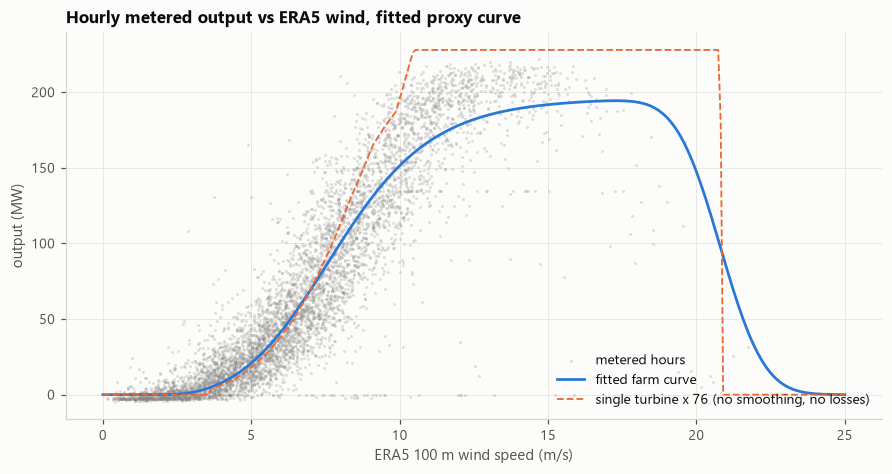

In [4]:
clean = clean_hours(panel)
pm = PowerModel(101).fit(clean["ws100"], clean["metered_mw"])
print(pm.params())
sample = clean.sample(6000, random_state=0)
v = np.linspace(0, 25, 300)

f, ax = fig(figsize=(8, 4.2))
ax.scatter(sample["ws100"], sample["metered_mw"], s=4, color=GREY, alpha=0.25, lw=0, label="metered hours")
ax.plot(v, pm.predict_mw(v), color=BLUE, label="fitted farm curve")
single = 228 * np.interp(pm.a * v + pm.b, GRID, turbine_curve(101) / 3000)
ax.plot(v, single, color=ORANGE, lw=1.2, ls="--", label="single turbine x 76 (no smoothing, no losses)")
ax.set_xlabel("ERA5 100 m wind speed (m/s)"); ax.set_ylabel("output (MW)")
ax.set_title("Hourly metered output vs ERA5 wind, fitted proxy curve")
ax.legend(loc="lower right")

The smoothed farm curve follows the cloud of points; the unsmoothed
single-turbine curve ramps too sharply. (A first version smoothed the cut-out
with the same widening Gaussian, which pulled the curve down from 15 m/s;
the data stays flat there, so cut-out now has its own narrow spread.) The scatter around the curve at a
given wind speed is the hourly error, mostly ERA5 not resolving local
gusts and wind direction effects.

,metered_gwh,model_gwh,error_pct
time,,,
2025-07-01 00:00:00+00:00,27.9,30.5,9.2
2025-08-01 00:00:00+00:00,38.3,41.7,8.8
2025-09-01 00:00:00+00:00,53.1,53.0,-0.1
2025-10-01 00:00:00+00:00,60.1,58.2,-3.1
2025-11-01 00:00:00+00:00,70.2,68.2,-2.7
2025-12-01 00:00:00+00:00,90.0,83.7,-7.0


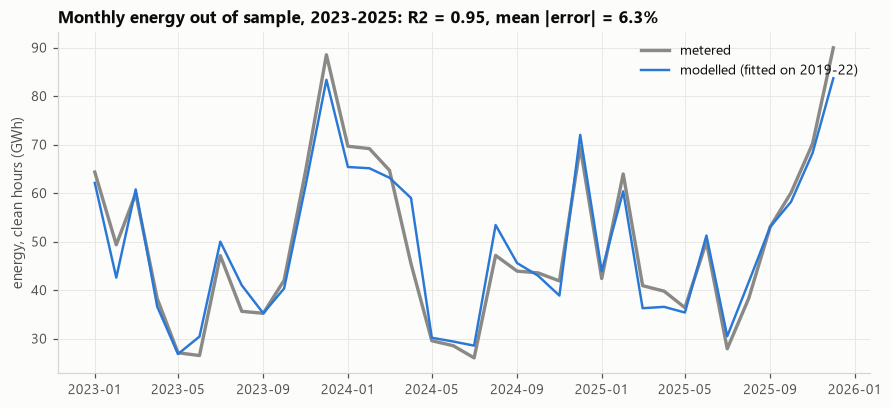

In [5]:
train, test = clean[:"2022"], clean["2023":]
pm_oos = PowerModel(101).fit(train["ws100"], train["metered_mw"])
me = monthly_energy(test, pm_oos)
r2 = 1 - ((me.model_gwh - me.metered_gwh)**2).sum() / ((me.metered_gwh - me.metered_gwh.mean())**2).sum()

f, ax = fig(figsize=(8, 3.6))
ax.plot(me.index, me.metered_gwh, color=GREY, lw=2.2, label="metered")
ax.plot(me.index, me.model_gwh, color=BLUE, lw=1.6, label="modelled (fitted on 2019-22)")
ax.set_ylabel("energy, clean hours (GWh)")
ax.set_title(f"Monthly energy out of sample, 2023-2025: R2 = {r2:.2f}, mean |error| = {me.error_pct.abs().mean():.1f}%")
ax.legend(loc="upper right")
me.round(1).tail(6)

**Milestone 1 result.** Out of sample, modelled monthly energy tracks
metered energy with R2 around 0.94 and a typical monthly error of ~6%.
The annual totals are close to unbiased. This is good enough to be the
proxy-generation formula of the swap; the remaining error is the
farm's operational risk, which it keeps.